# Next Word Prediction Model using LSTM

**Dataset:** [Next Word Prediction (Kaggle)](https://www.kaggle.com/datasets/ronikdedhia/next-word-prediction) 

In [ ]:
import os
import re
import json
import time
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## 1. Load Dataset

In [ ]:
CANDIDATES = [
    "data/1661-0.txt",
    "1661-0.txt",
    "/content/1661-0.txt",
    "/kaggle/input/next-word-prediction/1661-0.txt",
]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))

with open(DATA_PATH, "r", encoding="utf-8-sig") as f:
    raw_text = f.read()

print("File:", DATA_PATH)
print("Characters:", len(raw_text))
print(raw_text[:400])

File: data/1661-0.txt
Characters: 581887

Project Gutenberg's The Adventures of Sherlock Holmes, by Arthur Conan Doyle

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included
with this eBook or online at www.gutenberg.net


Title: The Adventures of Sherlock Holmes

Author: Arthur Conan Doyle




## 2. Text Cleaning

In [ ]:
start = raw_text.find("*** START OF")
end = raw_text.find("*** END OF")
text = raw_text[raw_text.find("\n", start) + 1 : end]

text = text.lower()
text = text.replace("\u2019", "'").replace("\u2018", "'")
text = re.sub(r"[^a-z' ]+", " ", text)
text = re.sub(r"\s+", " ", text).strip()

words = text.split()
print("Total words :", len(words))
print("Unique words:", len(set(words)))
print(" ".join(words[:60]))

Total words : 105753
Unique words: 8115
produced by an anonymous project gutenberg volunteer and jose menendez cover the adventures of sherlock holmes by arthur conan doyle contents i a scandal in bohemia ii the red headed league iii a case of identity iv the boscombe valley mystery v the five orange pips vi the man with the twisted lip vii the adventure of the blue carbuncle


## 3. Tokenization

In [ ]:
VOCAB_SIZE = 4000
PAD, UNK = "<pad>", "<unk>"

most_common = [w for w, _ in Counter(words).most_common(VOCAB_SIZE - 2)]
index_word = {0: PAD, 1: UNK}
index_word.update({i + 2: w for i, w in enumerate(most_common)})
word_index = {w: i for i, w in index_word.items()}
vocab_size = len(word_index)


def clean(sentence):
    sentence = sentence.lower().replace("\u2019", "'")
    return re.sub(r"[^a-z' ]+", " ", sentence).split()


def encode(tokens):
    return [word_index.get(t, word_index[UNK]) for t in tokens]


sequence = np.array(encode(words))
unk_share = np.mean(sequence == word_index[UNK])

print("Vocabulary size:", vocab_size)
print("Token sequence length:", len(sequence))
print(f"Words mapped to <unk>: {unk_share:.1%}")

Vocabulary size: 4000
Token sequence length: 105753
Words mapped to <unk>: 4.4%


## 4. Create Training Sequences

In [ ]:
SEQ_LEN = 8

windows = np.lib.stride_tricks.sliding_window_view(sequence, SEQ_LEN + 1)
X, y = windows[:, :-1], windows[:, -1]

mask = y != word_index[UNK]
X, y = X[mask], y[mask]

perm = np.random.permutation(len(X))
X, y = X[perm], y[perm]

print("Input shape :", X.shape)
print("Target shape:", y.shape)
print("Example:", " ".join(index_word[i] for i in X[0]), "->", index_word[y[0]])

Input shape : (101146, 8)
Target shape: (101146,)
Example: whole garden has already been minutely examined now -> my


## 5. Build LSTM Model

In [6]:
import numpy as np


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


class LSTMLanguageModel:
    def __init__(self, vocab_size, embed_dim=64, hidden=192, dropout=0.3, seed=42):
        rng = np.random.default_rng(seed)
        self.V, self.E, self.H, self.dropout = vocab_size, embed_dim, hidden, dropout
        self.rng = rng
        H = hidden
        b = np.zeros(4 * H, dtype=np.float32)
        b[H:2 * H] = 1.0
        self.p = {
            "emb": (rng.standard_normal((vocab_size, embed_dim)) * 0.05).astype(np.float32),
            "Wx": (rng.standard_normal((embed_dim, 4 * H)) * np.sqrt(1 / embed_dim)).astype(np.float32),
            "Wh": (rng.standard_normal((H, 4 * H)) * np.sqrt(1 / H)).astype(np.float32),
            "b": b,
            "Wo": (rng.standard_normal((H, vocab_size)) * np.sqrt(1 / H)).astype(np.float32),
            "bo": np.zeros(vocab_size, dtype=np.float32),
        }
        self.m = {k: np.zeros_like(v) for k, v in self.p.items()}
        self.v = {k: np.zeros_like(v) for k, v in self.p.items()}
        self.t = 0

    def count_params(self):
        return sum(v.size for v in self.p.values())

    def forward(self, X, train=False):
        p, H = self.p, self.H
        B, T = X.shape
        emb = p["emb"][X]
        h = np.zeros((B, H), dtype=np.float32)
        c = np.zeros((B, H), dtype=np.float32)
        cache = []
        for t in range(T):
            z = emb[:, t] @ p["Wx"] + h @ p["Wh"] + p["b"]
            i, f = sigmoid(z[:, :H]), sigmoid(z[:, H:2 * H])
            g, o = np.tanh(z[:, 2 * H:3 * H]), sigmoid(z[:, 3 * H:])
            c_new = f * c + i * g
            tc = np.tanh(c_new)
            h_new = o * tc
            cache.append((h, c, i, f, g, o, tc))
            h, c = h_new, c_new
        mask = None
        hd = h
        if train and self.dropout > 0:
            mask = (self.rng.random(h.shape) >= self.dropout).astype(np.float32) / (1 - self.dropout)
            hd = h * mask
        logits = hd @ p["Wo"] + p["bo"]
        logits -= logits.max(axis=1, keepdims=True)
        e = np.exp(logits)
        probs = e / e.sum(axis=1, keepdims=True)
        return probs, (X, emb, cache, hd, mask)

    def loss_and_grads(self, X, y):
        p, H = self.p, self.H
        probs, (X, emb, cache, hd, mask) = self.forward(X, train=True)
        B, T = X.shape
        loss = -np.log(probs[np.arange(B), y] + 1e-12).mean()
        d = probs.copy()
        d[np.arange(B), y] -= 1
        d /= B
        g = {k: np.zeros_like(v) for k, v in p.items()}
        g["Wo"] = hd.T @ d
        g["bo"] = d.sum(0)
        dh = d @ p["Wo"].T
        if mask is not None:
            dh = dh * mask
        dc = np.zeros_like(dh)
        demb = np.zeros_like(emb)
        for t in reversed(range(T)):
            h_prev, c_prev, i, f, gg, o, tc = cache[t]
            do = dh * tc
            dc = dc + dh * o * (1 - tc ** 2)
            di, df, dg = dc * gg, dc * c_prev, dc * i
            dz = np.concatenate([di * i * (1 - i), df * f * (1 - f), dg * (1 - gg ** 2), do * o * (1 - o)], axis=1)
            g["Wx"] += emb[:, t].T @ dz
            g["Wh"] += h_prev.T @ dz
            g["b"] += dz.sum(0)
            demb[:, t] = dz @ p["Wx"].T
            dh = dz @ p["Wh"].T
            dc = dc * f
        np.add.at(g["emb"], X, demb)
        return loss, g

    def step(self, grads, lr, clip=5.0, b1=0.9, b2=0.999, eps=1e-8):
        norm = np.sqrt(sum(float((v ** 2).sum()) for v in grads.values()))
        scale = min(1.0, clip / (norm + 1e-9))
        self.t += 1
        for k in self.p:
            gk = grads[k] * scale
            self.m[k] = b1 * self.m[k] + (1 - b1) * gk
            self.v[k] = b2 * self.v[k] + (1 - b2) * gk * gk
            mh = self.m[k] / (1 - b1 ** self.t)
            vh = self.v[k] / (1 - b2 ** self.t)
            self.p[k] -= (lr * mh / (np.sqrt(vh) + eps)).astype(np.float32)

    def predict(self, X, batch_size=512, verbose=0):
        X = np.asarray(X)
        out = [self.forward(X[i:i + batch_size])[0] for i in range(0, len(X), batch_size)]
        return np.concatenate(out)

    def evaluate(self, X, y, batch_size=1024):
        loss, correct = 0.0, 0
        for i in range(0, len(X), batch_size):
            pr = self.forward(X[i:i + batch_size])[0]
            yy = y[i:i + batch_size]
            loss += -np.log(pr[np.arange(len(yy)), yy] + 1e-12).sum()
            correct += (pr.argmax(1) == yy).sum()
        return loss / len(X), correct / len(X)

    def get_weights(self):
        return {k: v.copy() for k, v in self.p.items()}

    def set_weights(self, w):
        self.p = {k: v.copy() for k, v in w.items()}


EMBED_DIM, HIDDEN = 64, 128
model = LSTMLanguageModel(vocab_size, embed_dim=EMBED_DIM, hidden=HIDDEN, dropout=0.3, seed=SEED)

print("Architecture: Embedding({}, {}) -> LSTM({}) -> Dropout(0.3) -> Dense({}, softmax)".format(vocab_size, EMBED_DIM, HIDDEN, vocab_size))
print("Trainable parameters:", f"{model.count_params():,}")

Architecture: Embedding(4000, 64) -> LSTM(128) -> Dropout(0.3) -> Dense(4000, softmax)
Trainable parameters: 870,816


## 6. Train Model

In [7]:
class History:
    def __init__(self):
        self.history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}


n_val = int(len(X) * 0.1)
X_train, y_train = X[:-n_val], y[:-n_val]
X_val, y_val = X[-n_val:], y[-n_val:]

EPOCHS, BATCH, PATIENCE = 14, 256, 3
lr = 3e-3
history = History()
best_val, best_weights, wait = np.inf, None, 0

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    order = np.random.permutation(len(X_train))
    total_loss, n_batches = 0.0, 0
    for i in range(0, len(order), BATCH):
        idx = order[i:i + BATCH]
        loss, grads = model.loss_and_grads(X_train[idx], y_train[idx])
        model.step(grads, lr)
        total_loss += loss
        n_batches += 1

    tr_loss, tr_acc = model.evaluate(X_train[:10000], y_train[:10000])
    val_loss, val_acc = model.evaluate(X_val, y_val)
    for k, v in zip(history.history, [tr_loss, tr_acc, val_loss, val_acc]):
        history.history[k].append(float(v))

    print(f"Epoch {epoch:2d}/{EPOCHS} - {time.time() - start:5.1f}s - lr {lr:.5f} - loss {tr_loss:.4f} - acc {tr_acc:.4f} - val_loss {val_loss:.4f} - val_acc {val_acc:.4f}")

    if val_loss < best_val - 1e-4:
        best_val, best_weights, wait = val_loss, model.get_weights(), 0
    else:
        wait += 1
        lr *= 0.5
        if wait >= PATIENCE:
            print("Early stopping")
            break

model.set_weights(best_weights)

Epoch  1/14 -  49.8s - lr 0.00300 - loss 5.4563 - acc 0.1156 - val_loss 5.5885 - val_acc 0.1086
Epoch  2/14 -  40.9s - lr 0.00300 - loss 5.0272 - acc 0.1503 - val_loss 5.2970 - val_acc 0.1390
Epoch  3/14 -  41.5s - lr 0.00300 - loss 4.7374 - acc 0.1638 - val_loss 5.1580 - val_acc 0.1418
Epoch  4/14 -  41.8s - lr 0.00300 - loss 4.5005 - acc 0.1815 - val_loss 5.0854 - val_acc 0.1488
Epoch  5/14 -  45.2s - lr 0.00300 - loss 4.2963 - acc 0.1937 - val_loss 5.0609 - val_acc 0.1526
Epoch  6/14 -  36.5s - lr 0.00300 - loss 4.0933 - acc 0.2080 - val_loss 5.0498 - val_acc 0.1562
Epoch  7/14 -  35.9s - lr 0.00300 - loss 3.9002 - acc 0.2252 - val_loss 5.0595 - val_acc 0.1549
Epoch  8/14 -  37.6s - lr 0.00150 - loss 3.7266 - acc 0.2414 - val_loss 5.0785 - val_acc 0.1549
Epoch  9/14 -  37.6s - lr 0.00075 - loss 3.6385 - acc 0.2536 - val_loss 5.1038 - val_acc 0.1558
Early stopping


## 7. Training Results

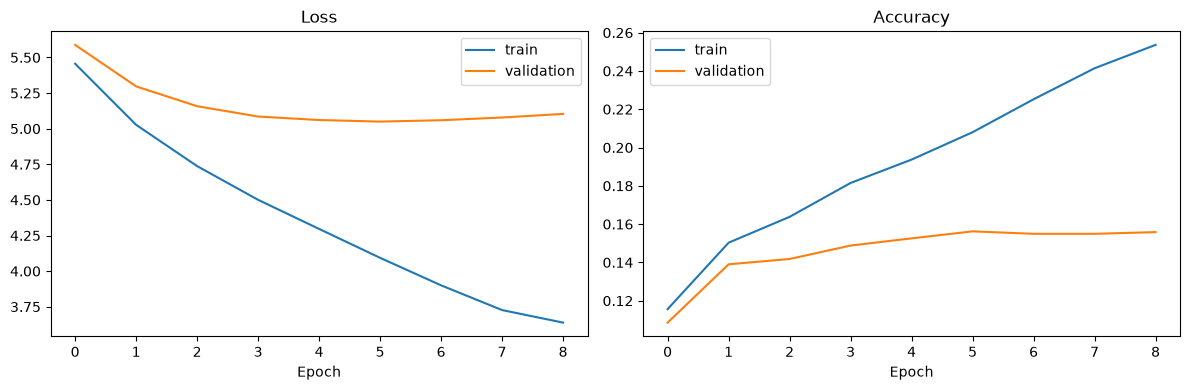

Best epoch           : 6
Validation loss      : 5.0498
Validation accuracy  : 0.1562
Validation perplexity: 156.0


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.tight_layout()
plt.show()

best = int(np.argmin(history.history["val_loss"]))
print(f"Best epoch           : {best + 1}")
print(f"Validation loss      : {history.history['val_loss'][best]:.4f}")
print(f"Validation accuracy  : {history.history['val_accuracy'][best]:.4f}")
print(f"Validation perplexity: {np.exp(history.history['val_loss'][best]):.1f}")

## 8. Next Word Prediction Functions

In [9]:
def to_input(sentence):
    seq = encode(clean(sentence))[-SEQ_LEN:]
    return [0] * (SEQ_LEN - len(seq)) + seq


def next_word_probs(sentence):
    probs = model.predict(np.array([to_input(sentence)]), verbose=0)[0].astype("float64")
    probs[[word_index[PAD], word_index[UNK]]] = 0
    return probs / probs.sum()


def predict_next_words(sentence, top_k=5):
    probs = next_word_probs(sentence)
    top = np.argsort(probs)[::-1][:top_k]
    return [(index_word[i], float(probs[i])) for i in top]


def generate_text(seed_text, n_words=10, temperature=0.7):
    out = seed_text
    for _ in range(n_words):
        probs = np.log(next_word_probs(out) + 1e-9) / temperature
        probs = np.exp(probs - probs.max())
        probs /= probs.sum()
        out += " " + index_word[np.random.choice(len(probs), p=probs)]
    return out

## 9. Test with Different Input Sentences

In [10]:
test_sentences = [
    "I have seen the",
    "Sherlock Holmes was sitting in his",
    "It is a capital mistake to",
    "My dear Watson, you have",
    "He took a large",
    "The man was tall and",
    "I could not help",
    "What do you make of",
    "There was a knock at the",
    "She had a very",
]

for s in test_sentences:
    preds = predict_next_words(s, top_k=5)
    print(f"Input : {s} ...")
    print(f"Best  : {preds[0][0]}")
    print("Top 5 : " + ", ".join(f"{w} ({p:.1%})" for w, p in preds))
    print()

Input : I have seen the ...
Best  : same
Top 5 : same (3.3%), matter (3.2%), facts (2.7%), police (1.8%), first (1.4%)

Input : Sherlock Holmes was sitting in his ...
Best  : chair
Top 5 : chair (9.3%), face (6.5%), hands (6.3%), hand (4.9%), head (4.4%)

Input : It is a capital mistake to ...
Best  : be
Top 5 : be (6.6%), the (6.1%), my (2.7%), have (2.5%), do (2.3%)

Input : My dear Watson, you have ...
Best  : done
Top 5 : done (7.3%), been (5.8%), already (3.9%), not (3.5%), no (3.2%)

Input : He took a large ...
Best  : villa
Top 5 : villa (3.2%), face (2.0%), volume (1.8%), line (1.5%), iron (1.2%)

Input : The man was tall and ...
Best  : yet
Top 5 : yet (2.9%), i (2.3%), a (2.1%), in (1.4%), he (1.4%)

Input : I could not help ...
Best  : him
Top 5 : him (14.8%), you (12.8%), me (8.5%), the (7.2%), to (5.6%)

Input : What do you make of ...
Best  : the
Top 5 : the (18.5%), my (10.4%), a (8.2%), your (3.8%), it (3.2%)

Input : There was a knock at the ...
Best  : room
Top 5 : ro

## 10. Accuracy on Held-out Data

In [11]:
probs = model.predict(X_val)
top1 = np.mean(np.argmax(probs, axis=1) == y_val)
top5 = np.mean((np.argsort(probs, axis=1)[:, -5:] == y_val[:, None]).any(axis=1))

print(f"Top-1 accuracy: {top1:.2%}")
print(f"Top-5 accuracy: {top5:.2%}")

Top-1 accuracy: 15.62%
Top-5 accuracy: 33.40%


## 11. Text Generation Examples

In [12]:
for seed in ["Holmes looked at me", "The king of", "I think that you"]:
    print(generate_text(seed, n_words=12))
    print()

Holmes looked at me that he had returned on his life i wish you know that

The king of bohemia said he the same was standing in his eyes ran with

I think that you are all the list of the injuries which had been wrongfully known



## 12. Save Model

In [13]:
np.savez("next_word_lstm_weights.npz", **model.p)
with open("vocab.json", "w") as f:
    json.dump(index_word, f)
print("Saved: next_word_lstm_weights.npz, vocab.json")

Saved: next_word_lstm_weights.npz, vocab.json



## Conclusion

- An LSTM language model, written from scratch in NumPy, was trained on *The Adventures of Sherlock Holmes* with an 8-word context window.
- `predict_next_words()` returns the top-k most probable next words with their probabilities.
- `generate_text()` repeatedly predicts words to continue a seed sentence.
- Predictions follow the style and vocabulary of the book, since the model learns only from this single text.